# 12 — Skeletons over time: LSTM and GNN

**Part B — deep learning.** The CNNs (notebook 11) look at **one image**. Two problems stayed:
- they also use **something else than the visible person** (room, place of the crop…);
- one image does not show the **movement**, and the video decision stayed weak (49 of 70 videos).

Here the input is the **skeleton** (notebook 09) during the **last 1.5 seconds**. A skeleton does not show the walls and furniture, and 1.5 seconds contain the movement.

We compare 3 networks:
- a **one-frame network** (no time): our reference, to measure what time brings;
- an **LSTM**: reads the 45 skeletons one after the other, with a memory;
- a **GNN** (graph network): joints = nodes, bones = edges; it mixes each joint with its neighbours, then looks along time.

**Two questions:** (A) which posture now? (same task, frames and groups as part A and the CNNs), and (B) did a fall just happen? → one answer per video.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"          # needed for repeatable results on the GPU
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import accuracy_score, f1_score, average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

ROOT = Path("..") / "data" / "raw" / "urfd"
PROC = Path("..") / "data" / "processed"
NETS = PROC / "skeleton_nets"; NETS.mkdir(exist_ok=True)
NAMES = ["not lying", "falling", "lying"]
torch.use_deterministic_algorithms(True)                      # the same start gives the same result
torch.backends.cudnn.benchmark = False
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

torch 2.5.1+cu121 | NVIDIA GeForce RTX 4050 Laptop GPU


💡 **Interpretation:** PyTorch on the laptop GPU (RTX 4050), as in notebook 11.

## Step 1 — 13 joints, and what to do when nobody is found

We keep **13 of the 33 joints** (nose, shoulders, elbows, wrists, hips, knees, ankles): fingers and eyes are too small to help here. The **bones** between them make the graph.

When MediaPipe finds nobody, we **keep the last known skeleton** and add a flag *found = 0*. We never use the future, so the method could run live.

In [2]:
J = ["nose", "l_shoulder", "r_shoulder", "l_elbow", "r_elbow", "l_wrist", "r_wrist", "l_hip", "r_hip", "l_knee", "r_knee", "l_ankle", "r_ankle"]
BONES = [(0, 1), (0, 2), (1, 2), (1, 3), (3, 5), (2, 4), (4, 6), (1, 7), (2, 8), (7, 8), (7, 9), (9, 11), (8, 10), (10, 12)]

labels = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2]) for k in ["falls", "adls"]], ignore_index=True)
labels.columns = ["video", "frame", "frame_label"]
skel = pd.read_csv(PROC / "skeletons.csv").merge(labels, on=["video", "frame"], how="left").sort_values(["video", "frame"], ignore_index=True)
xy = np.stack([np.stack([skel[f"{j}_x"] * 640 / 480, skel[f"{j}_y"]], -1) for j in J], 1)      # rows x 13 x 2, in image heights
found = skel.detected.to_numpy()
VIDEO_ROWS = {v: np.sort(idx) for v, idx in skel.groupby("video").indices.items()}
for idx in VIDEO_ROWS.values():                                                                # keep the last known skeleton
    xy[idx] = pd.DataFrame(xy[idx].reshape(len(idx), -1)).ffill().to_numpy().reshape(len(idx), 13, 2)

test_rows = pd.read_csv(PROC / "predictions_hog.csv")[["video", "frame"]]                      # the same 11,027 frames as part A and the CNNs
rows = test_rows.merge(skel[["video", "frame"]].reset_index(), on=["video", "frame"], how="left")["index"].to_numpy()
y = skel.frame_label.to_numpy()[rows].astype(int) + 1
fall_row = skel.video.str.startswith("fall").to_numpy()
fall_frame = fall_row[rows]

videos = np.array(sorted(skel.video.unique()))
random_of = {}
for k, (_, test) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(videos, np.char.startswith(videos.astype(str), "fall").astype(int))):
    random_of.update({v: k + 1 for v in videos[test]})
strict_of = pd.read_csv(Path("..") / "video_groups.csv").set_index("video").group.to_dict()
GROUP_OF = {"strict": strict_of, "random": random_of}
GROUPS = {name: skel.video.map(of).to_numpy() for name, of in GROUP_OF.items()}
print(len(skel), "skeleton frames,", len(rows), "test frames | share of the test frames where a person is found:")
pd.DataFrame({"ADL videos": [found[rows][(y == k) & ~fall_frame].mean() for k in range(3)], "fall videos": [found[rows][(y == k) & fall_frame].mean() for k in range(3)]}, index=NAMES).round(2)

11936 skeleton frames, 11027 test frames | share of the test frames where a person is found:


,ADL videos,fall videos
not lying,0.89,1.00
falling,1.00,0.98
lying,0.62,0.78


💡 **Interpretation:** on the 11,027 test frames, people are found almost always when they stand or go down in the falls, but only in **62%** (ADLs) and **78%** (falls) of the *lying* frames.
So many *lying* frames must be recognised from the last known skeleton: this is the main difficulty of skeletons.

## Step 2 — Windows of 1.5 seconds, without the place in the image

For each frame we take the **45 frames that end there** (1.5 s). Each window is then **centred and scaled**:
- subtract the average position of the hips in the window (the place in the room disappears);
- divide by the torso length (near or far from the camera gives the same size).

The **movement inside the window stays** (the hips still go down). For each joint: x, y, their change since the previous frame, and *found*. At the start of a video, the missing past is filled with the first frame and *found = 0*.

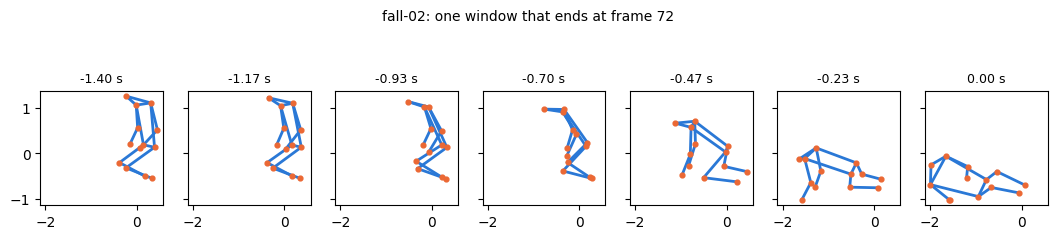

windows: (11936, 45, 13, 5)


In [3]:
T = 45
def make_windows():
    out = np.zeros((len(skel), T, 13, 5), np.float32)
    for idx in VIDEO_ROWS.values():
        P, ok = xy[idx], found[idx]
        for t in range(len(idx)):
            real = np.arange(t - T + 1, t + 1) >= 0
            w = np.clip(np.arange(t - T + 1, t + 1), 0, None)
            p = P[w]
            if np.isnan(p[:, 0, 0]).all(): continue                                             # nobody seen yet: zeros
            hips, shoulders = p[:, 7:9].mean(1), p[:, 1:3].mean(1)
            torso = np.linalg.norm(shoulders - hips, axis=1)
            q = (p - np.nanmean(hips, axis=0)) / max(np.nanpercentile(torso, 90), 0.05)
            d = np.zeros_like(q); d[1:] = (q[1:] - q[:-1]) * 10
            f = np.broadcast_to((ok[w] & real)[:, None, None], (T, 13, 1))
            out[idx[t]] = np.nan_to_num(np.concatenate([q, d, f], -1)).clip(-10, 10)
    return out
X = torch.from_numpy(make_windows()).to(device)

end = skel.index[(skel.video == "fall-02") & (skel.frame == 72)][0]
fig, axes = plt.subplots(1, 7, figsize=(13, 2.5), sharex=True, sharey=True)
for ax, t in zip(axes, range(2, 45, 7)):
    p = X[end, t, :, :2].cpu().numpy()
    for a, b in BONES: ax.plot(p[[a, b], 0], -p[[a, b], 1], color="#2a78d6", lw=2)
    ax.scatter(p[:, 0], -p[:, 1], color="#eb6834", s=12, zorder=3); ax.set_title(f"{(t - 44) / 30:.2f} s", fontsize=9); ax.set_aspect("equal")
plt.suptitle("fall-02: one window that ends at frame 72", fontsize=10, y=1.05); plt.show()
print("windows:", tuple(X.shape))

💡 **Interpretation:** the 7 skeletons show the fall: upright at −1.4 s, bending at −0.7 s, flat at 0 s. The room is gone, but the downward movement is still visible.
One window = 45 frames × 13 joints × 5 values (x, y, their change, *found*).

## Step 3 — The three networks

All are small and trained **from scratch** (no pretrained weights). The one-frame network only sees the **last** skeleton, centred on its own hips. The other two see the whole window.

In [4]:
class OneFrame(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(13 * 2 + 1, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, n))
    def forward(self, w):
        p = w[:, -1, :, :2]; p = p - p[:, [7, 8]].mean(1, keepdim=True)      # 7 and 8 = hips
        return self.net(torch.cat([p.flatten(1), w[:, -1, :1, 4]], 1))

class LSTM(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.lstm = nn.LSTM(13 * 4 + 1, 64, batch_first=True); self.out = nn.Sequential(nn.Dropout(0.3), nn.Linear(64, n))
    def forward(self, w):
        return self.out(self.lstm(torch.cat([w[..., :4].flatten(2), w[:, :, 0, 4:5]], 2))[0][:, -1])

A = torch.eye(13)
for a, b in BONES: A[a, b] = A[b, a] = 1
A = A / A.sum(1, keepdim=True)                      # each joint = average of itself and its neighbours

class Block(nn.Module):                             # 1) mix neighbouring joints, 2) look along time
    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.register_buffer("A", A.clone()); self.importance = nn.Parameter(torch.ones(13, 13))
        self.mix = nn.Conv2d(c_in, c_out, 1)
        self.time = nn.Sequential(nn.BatchNorm2d(c_out), nn.ReLU(), nn.Conv2d(c_out, c_out, (9, 1), (stride, 1), (4, 0)), nn.BatchNorm2d(c_out), nn.Dropout(0.3))
        self.skip = nn.Conv2d(c_in, c_out, 1, (stride, 1))
    def forward(self, x):
        return torch.relu(self.time(torch.einsum("bctv,wv->bctw", self.mix(x), self.A * self.importance)) + self.skip(x))

class GNN(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.blocks = nn.Sequential(Block(5, 32, 1), Block(32, 32, 2), Block(32, 64, 2)); self.out = nn.Linear(64, n)
    def forward(self, w):
        return self.out(self.blocks(w.permute(0, 3, 1, 2)).mean((2, 3)))

MODELS = {"one frame": OneFrame, "LSTM": LSTM, "GNN": GNN}
table = []
for name, M in MODELS.items():
    net = M(3).to(device).eval(); w = X[:64]
    with torch.no_grad():
        for _ in range(5): net(w)
        if device == "cuda": torch.cuda.synchronize()
        t = time.time()
        for _ in range(50): net(w)
        if device == "cuda": torch.cuda.synchronize()
    table.append({"network": name, "parameters (thousands)": sum(p.numel() for p in net.parameters()) / 1e3, "ms per window (batch of 64)": (time.time() - t) / 50 / 64 * 1000})
sizes = pd.DataFrame(table).round(3); sizes

,network,parameters (thousands),ms per window (batch of 64)
0,one frame,12.291,0.006
1,LSTM,30.659,0.007
2,GNN,63.358,0.025


💡 **Interpretation:** all three are tiny: 12 to 63 thousand parameters (MobileNetV2 has 2.2 million), and far below 1 ms per window on the GPU.
MediaPipe, which finds the skeleton first, is not counted here.

## Step 4 — How we train (same protocol as the CNNs)

- test group *k*, **validation = next group**, training = the 3 others, 1 window out of 2; 20 epochs, and we keep the **best epoch on the validation group**;
- **class weights**, weight decay, dropout, and small changes of the skeletons: left-right flip, size × 0.9-1.1, noise on the joints;
- **3 random starts** with the strict groups, 1 with the random groups. Results are saved, so a rerun is fast.

**Task A (posture):** target = label of the last frame of the window.
**Task B (fall):** target = 1 when a window of a **fall video** contains at least half a second (15 frames) of the *falling* label; 0 for all ADL windows and for fall-video windows before the fall. The other windows (start of the fall, long after it) are not used for training.

For task B, the validation score is the average precision of the fall windows (1 = every fall window has a higher score than all the others).

In [5]:
FLIP = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11]
def augment(w):
    w = w.clone()
    f = torch.rand(len(w), device=w.device) < 0.5
    w[f] = w[f][:, :, FLIP] * torch.tensor([-1, 1, -1, 1, 1.0], device=w.device)
    w[..., :4] *= torch.empty(len(w), 1, 1, 1, device=w.device).uniform_(0.9, 1.1)
    w[..., :2] += 0.02 * torch.randn_like(w[..., :2])
    return w

falling = (skel.frame_label == 0).to_numpy()
in_window = np.zeros(len(skel))
for idx in VIDEO_ROWS.values(): in_window[idx] = pd.Series(falling[idx].astype(float)).rolling(T, min_periods=1).sum().to_numpy()
before = (in_window == 0) & (skel.frame_label == -1).to_numpy()
y_fall = np.where(fall_row & (in_window >= 15), 1, np.where(~fall_row | before, 0, -1))

y_posture = np.full(len(skel), -1); y_posture[rows] = y
TASKS = {"posture": (y_posture, 3), "fall": (y_fall, 2)}

def scores_of(net, index):
    net.eval()
    with torch.no_grad():
        return torch.cat([net(X[b]).softmax(1) for b in torch.split(index, 2048)]).cpu().numpy()

def train_one(task, name, groups, test, seed, epochs=20, use=None):
    target, n = TASKS[task]; g, val = GROUPS[groups], test % 5 + 1
    tr = torch.from_numpy(np.flatnonzero((g != test) & (g != val) & (target >= 0))[::2]).to(device)
    va = torch.from_numpy(np.flatnonzero((g == val) & (target >= 0))).to(device)
    Y = torch.from_numpy(target).to(device)
    torch.manual_seed(seed)
    net = MODELS[name](n)
    net = (net if use is None else use(net)).to(device)
    weight = 1 / torch.bincount(Y[tr], minlength=n).float()
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-2)
    def score(index):
        p, t = scores_of(net, index), target[index.cpu().numpy()]
        return f1_score(t, p.argmax(1), average="macro") if task == "posture" else average_precision_score(t, p[:, 1])
    best, state, history = -1, None, []
    for epoch in range(epochs):
        net.train(); total = 0
        for b in torch.split(tr[torch.randperm(len(tr), device=device)], 128):
            if len(b) < 2: continue
            loss = nn.functional.cross_entropy(net(augment(X[b])), Y[b], weight=weight / weight.mean())
            opt.zero_grad(); loss.backward(); opt.step(); total += loss.item() * len(b)
        history.append({"groups": groups, "network": name, "seed": seed, "test": test, "epoch": epoch + 1, "train loss": total / len(tr), "train": score(tr), "val": score(va)})
        if history[-1]["val"] > best: best, state = history[-1]["val"], {k: v.detach().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(state)
    return net, pd.DataFrame(history)

def run(task, name, groups, seed, use=None, tag=""):
    """Scores of every skeleton frame: p = from the network whose TEST group holds the frame, val_p = from the one whose VALIDATION group holds it."""
    stem = f"{task}_{groups}_{name}{tag}_{seed}".replace(" ", "_")
    file, hist_file = NETS / f"{stem}.csv", NETS / f"{stem}_history.csv"
    if file.exists() and hist_file.exists(): return pd.read_csv(file), pd.read_csv(hist_file)
    n = TASKS[task][1]; out, val_out, hist = np.zeros((len(skel), n)), np.zeros((len(skel), n)), []
    for test in range(1, 6):
        net, h = train_one(task, name, groups, test, seed, use=use); hist.append(h)
        for store, k in [(out, test), (val_out, test % 5 + 1)]:
            idx = np.flatnonzero(GROUPS[groups] == k); store[idx] = scores_of(net, torch.from_numpy(idx).to(device))
    df = pd.DataFrame(np.hstack([out, val_out]).round(5), columns=[f"p{k}" for k in range(n)] + [f"val_p{k}" for k in range(n)])
    hist = pd.concat(hist, ignore_index=True); hist.to_csv(hist_file, index=False); df.to_csv(file, index=False)
    return df, hist

t = time.time()
results = {}
for task in TASKS:
    for name in MODELS:
        for s in range(3): results[task, name, "strict", s] = run(task, name, "strict", s)
        results[task, name, "random", 0] = run(task, name, "random", 0)
print(f"{(time.time() - t) / 60:.1f} min (0 if loaded from the saved files)")
pd.DataFrame({"windows of task B": [(y_fall == k).sum() for k in (1, 0, -1)]}, index=["fall", "no fall", "not used"])

0.0 min (0 if loaded from the saved files)


,windows of task B
fall,1133
no fall,10133
not used,670


💡 **Interpretation:** task B has 1,133 fall windows against 10,133 others (10%), so the class weights are needed; 670 windows are not used for training.
The saved results are loaded here (training took about 12 minutes). Repeatable GPU settings are on: the same start always gives the same network.

posture - last epoch: {'one frame': {'train': 0.88, 'val': 0.74}, 'LSTM': {'train': 0.93, 'val': 0.73}, 'GNN': {'train': 0.91, 'val': 0.63}}
fall - last epoch: {'one frame': {'train': 0.98, 'val': 0.6}, 'LSTM': {'train': 1.0, 'val': 0.9}, 'GNN': {'train': 1.0, 'val': 0.96}}


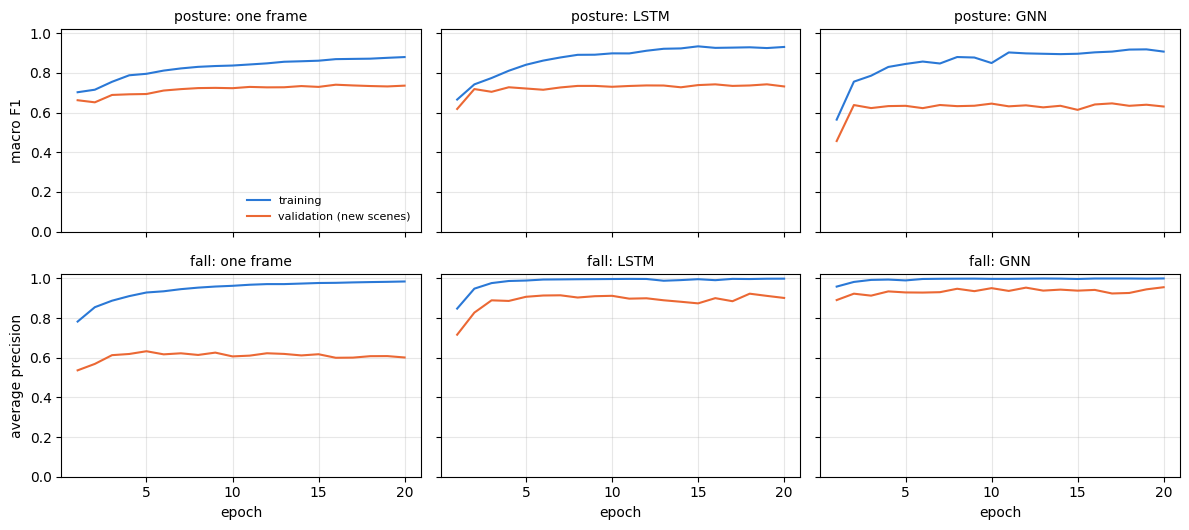

,posture: best validation macro F1,fall: best validation average precision
network,,
one frame,0.761,0.673
LSTM,0.800,0.963
GNN,0.712,0.975


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.4), sharex=True, sharey="row")
best_val = {}
for r, (task, label) in enumerate([("posture", "macro F1"), ("fall", "average precision")]):
    h = pd.concat([results[task, n, "strict", s][1] for n in MODELS for s in range(3)], ignore_index=True)
    for ax, name in zip(axes[r], MODELS):
        c = h[h.network == name].groupby("epoch")[["train", "val"]].mean()
        ax.plot(c.index, c.train, color="#2a78d6", label="training"); ax.plot(c.index, c.val, color="#eb6834", label="validation (new scenes)")
        ax.set_title(f"{task}: {name}", fontsize=10); ax.grid(alpha=0.3); ax.set_ylim(0, 1.02)
    axes[r, 0].set_ylabel(label)
    best_val[task] = h.groupby(["network", "seed", "test"]).val.max().groupby("network").mean().loc[list(MODELS)].round(3)
    print(task, "- last epoch:", h[h.epoch == h.epoch.max()].groupby("network")[["train", "val"]].mean().round(2).loc[list(MODELS)].to_dict("index"))
for ax in axes[1]: ax.set_xlabel("epoch")
axes[0, 0].legend(fontsize=8, frameon=False, loc="lower right"); plt.tight_layout(); plt.show()
pd.DataFrame(best_val).rename(columns={"posture": "posture: best validation macro F1", "fall": "fall: best validation average precision"})

💡 **Interpretation:** time helps in the **validation**: LSTM 0.800 for postures (one frame 0.761, GNN 0.712), and 0.963 (LSTM) / 0.975 (GNN) for falls (one frame 0.673). The GNN is first for falls and last for postures.
Training is close to 1.0 for falls, and the gap with validation is smaller than for the CNNs (0.99 vs 0.66-0.68 in notebook 11), but still visible for postures.

## Step 5 — Task A: postures, compared with the other methods

Same 11,027 frames and groups everywhere. The networks of this notebook and the CNNs learn from 3 groups, part A from 4. Neural networks: average of 3 random starts.

In [7]:
def posture(name, groups, s): return results["posture", name, groups, s][0][["p0", "p1", "p2"]].to_numpy()[rows].argmax(1)
def line(method, preds, random=None):
    f = [f1_score(y, p, average="macro") for p in preds]
    return {"method": method, "accuracy (strict)": np.mean([accuracy_score(y, p) for p in preds]), "macro F1 (strict)": np.mean(f), "lowest": min(f), "highest": max(f),
            "macro F1 (random)": np.nan if random is None else f1_score(y, random, average="macro")}
cnn, part_a = pd.read_csv(PROC / "predictions_cnn.csv"), pd.read_csv(PROC / "predictions_strict.csv")
assert cnn[["video", "frame"]].equals(test_rows) and part_a[["video", "frame"]].equals(test_rows)
table = [line(f"skeleton: {n}", [posture(n, "strict", s) for s in range(3)], posture(n, "random", 0)) for n in MODELS]
table += [line(f"CNN: {n}", [cnn[f"strict {n} {s}"].to_numpy() + 1 for s in range(3)], cnn[f"random {n} 0"].to_numpy() + 1) for n in ["MobileNetV2", "ResNet50"]]
table += [line(f"part A: {m}", [part_a[m].astype(int).to_numpy() + 1]) for m in ["HOG + SVM", "Colour (HSV) + SVM"]]
frame_scores = pd.DataFrame(table).round(3); frame_scores

,method,accuracy (strict),macro F1 (strict),lowest,highest,macro F1 (random)
0,skeleton: one frame,0.783,0.715,0.698,0.725,0.795
1,skeleton: LSTM,0.806,0.752,0.723,0.787,0.812
2,skeleton: GNN,0.733,0.659,0.632,0.696,0.786
3,CNN: MobileNetV2,0.755,0.689,0.677,0.708,0.845
4,CNN: ResNet50,0.746,0.671,0.665,0.682,0.856
5,part A: HOG + SVM,0.749,0.639,0.639,0.639,NaN
6,part A: Colour (HSV) + SVM,0.784,0.662,0.662,0.662,NaN


💡 **Interpretation:** the **LSTM is the best of all** on the strict groups: macro F1 **0.752** (0.723-0.787) and accuracy **0.806**, above the CNNs (0.689) and colour + SVM (0.662 and 0.784). Even one frame (0.715) beats the CNNs.
From random to strict groups the LSTM loses 0.06 and the CNNs 0.16 to 0.19: skeletons depend less on the scene. The GNN (0.659) is not better than the CNNs here.

In [8]:
def recognised(p):
    r = {f"{NAMES[k]} in {kind} videos": np.mean(p[m & (y == k)] == k) for kind, m in [("ADL", ~fall_frame), ("fall", fall_frame)] for k in (1, 2)}
    for lab, m in [("found", found[rows]), ("NOT found", ~found[rows])]: r[f"macro F1, person {lab}"] = f1_score(y[m], p[m], average="macro")
    return r
seen = {f"skeleton: {n}": pd.DataFrame([recognised(posture(n, "strict", s)) for s in range(3)]).mean() for n in MODELS}
seen |= {f"CNN: {n}": pd.DataFrame([recognised(cnn[f"strict {n} {s}"].to_numpy() + 1) for s in range(3)]).mean() for n in ["MobileNetV2", "ResNet50"]}
print("share of the test frames where MediaPipe finds nobody:", round(float((~found[rows]).mean()), 2))
pd.DataFrame(seen).T.round(2)

share of the test frames where MediaPipe finds nobody: 0.12


,falling in ADL videos,lying in ADL videos,falling in fall videos,lying in fall videos,"macro F1, person found","macro F1, person NOT found"
skeleton: one frame,0.72,0.58,0.63,0.88,0.73,0.52
skeleton: LSTM,0.49,0.90,0.73,0.90,0.77,0.59
skeleton: GNN,0.27,0.63,0.66,0.86,0.66,0.66
CNN: MobileNetV2,0.34,0.77,0.79,0.78,0.68,0.61
CNN: ResNet50,0.37,0.58,0.76,0.81,0.68,0.51


💡 **Interpretation:** in ADL rooms the LSTM recognises **90%** of *lying* and 49% of *falling* (CNNs at most 77% and 37%); the one-frame network sees 72% of *falling* in ADLs.
The weak point is when MediaPipe finds nobody (12% of the frames): macro F1 drops from 0.77 to 0.59 for the LSTM.

## Step 6 — Check: what does the *found* flag alone know?

MediaPipe loses lying people more often, and not equally in every room. So we train the same LSTM with **only the *found* flag** (all joints erased): what it reaches does not come from the skeleton.

In [9]:
class FlagOnly(nn.Module):
    def __init__(self, net): super().__init__(); self.net = net
    def forward(self, w):
        w = w.clone(); w[..., :4] = 0
        return self.net(w)
flag = {t: [run(t, "LSTM", "strict", s, use=FlagOnly, tag="_flag_only") for s in range(3)] for t in TASKS}
flag_posture = [flag["posture"][s][0][["p0", "p1", "p2"]].to_numpy()[rows].argmax(1) for s in range(3)]
print("posture, macro F1 | flag only:", round(np.mean([f1_score(y, p, average="macro") for p in flag_posture]), 3),
      "| LSTM:", frame_scores.set_index("method").loc["skeleton: LSTM", "macro F1 (strict)"], "| always 'not lying':", round(f1_score(y, np.zeros_like(y), average="macro"), 3))
m = y_fall >= 0
ap = lambda d: average_precision_score(y_fall[m], d.p1.to_numpy()[m])
print("fall windows, average precision | flag only:", round(np.mean([ap(flag["fall"][s][0]) for s in range(3)]), 3),
      "|", {n: round(float(np.mean([ap(results["fall", n, "strict", s][0]) for s in range(3)])), 3) for n in MODELS}, "| chance:", round(float(np.mean(y_fall[m] == 1)), 3))

posture, macro F1 | flag only: 0.38 | LSTM: 0.752 | always 'not lying': 0.26
fall windows, average precision | flag only: 0.163 | {'one frame': 0.33, 'LSTM': 0.779, 'GNN': 0.903} | chance: 0.101


💡 **Interpretation:** the *found* flag alone gives 0.38 for postures (always *not lying*: 0.26, LSTM: 0.752) and 0.163 for falls (chance: 0.101, LSTM: 0.779, GNN: 0.903).
So the scores of the LSTM and the GNN come mostly from the skeleton, not from the pattern of missing people.

## Step 7 — Task B: fall or no fall, one answer per video

1. each frame gets a fall score (the window that ends there), smoothed with a **median over the last 5 frames**;
2. video score = the **highest** score of the video;
3. video = *fall* if its score is above a **threshold chosen on the validation videos** (never on the test ones).

**For comparison,** the state machine (notebook 10) with its speed threshold chosen again on the **4 other groups** (its other thresholds were chosen by looking at all the videos, so it keeps an advantage).

In [10]:
is_fall = np.char.startswith(videos.astype(str), "fall").astype(int)
def smooth(p): return pd.Series(p).groupby(skel.video).transform(lambda s: s.rolling(5, min_periods=1).median())
def video_score(p): return smooth(p).groupby(skel.video).max().loc[videos].to_numpy()
def decide(d, groups):
    score, val, g = video_score(d.p1.to_numpy()), video_score(d.val_p1.to_numpy()), np.array([GROUP_OF[groups][v] for v in videos])
    pred, thr = np.zeros(70, int), {}
    for test in range(1, 6):
        v = g == test % 5 + 1
        grid = np.round(np.arange(0.05, 1, 0.05), 2); acc = np.array([np.mean((val[v] > t) == is_fall[v]) for t in grid])
        thr[test] = float(np.median(grid[acc == acc.max()])); pred[g == test] = score[g == test] > thr[test]
    return pred, score, thr
def video_line(method, preds):
    r = pd.DataFrame([{"videos right (of 70)": (p == is_fall).sum(), "falls caught (of 30)": p[is_fall == 1].sum(), "false alarms (of 40)": p[is_fall == 0].sum()} for p in preds])
    return {"method": method, **r.mean().round(1), "lowest-highest": f"{r.iloc[:, 0].min()}-{r.iloc[:, 0].max()}"}
decided = {(n, s): decide(results["fall", n, "strict", s][0], "strict") for n in MODELS for s in range(3)}
table = []
for n in MODELS:
    table.append(video_line(f"skeleton: {n}", [decided[n, s][0] for s in range(3)]) | {
        "AUC of the score": np.mean([roc_auc_score(is_fall, decided[n, s][1]) for s in range(3)]),
        "videos right, threshold 0.5": np.mean([((decided[n, s][1] > 0.5) == is_fall).sum() for s in range(3)]),
        "videos right, random groups": (decide(results["fall", n, "random", 0][0], "random")[0] == is_fall).sum()})
flag_dec = [decide(flag["fall"][s][0], "strict") for s in range(3)]
table.append(video_line("check: found flag only", [d[0] for d in flag_dec]) | {"AUC of the score": np.mean([roc_auc_score(is_fall, d[1]) for d in flag_dec])})

# the state machine of notebook 10
sm = skel[["video", "frame"]].copy()
hip_x, hip_y, sh_x, sh_y = [(skel[f"l_{j}_{c}"] + skel[f"r_{j}_{c}"]) / 2 for j in ["hip", "shoulder"] for c in "xy"]
sm["hip_height"] = 1 - hip_y; sm["angle"] = np.degrees(np.arctan2(np.abs(sh_x - hip_x) * 640, (hip_y - sh_y) * 480))
for c in ["hip_height", "angle"]:
    sm[c] = sm.groupby("video")[c].transform(lambda v: v.interpolate(limit=15, limit_area="inside").rolling(5, center=True, min_periods=1).median())
sm["speed"] = -sm.groupby("video").hip_height.diff() * 30
def state_machine(d, speed_fall):
    state, timer = "NORMAL", 0
    for height, angle, speed in zip(d.hip_height, d.angle, d.speed):
        missing = np.isnan(height) or np.isnan(angle); lying = not missing and (angle > 60 or height < 0.2)
        if state == "NORMAL":
            if not missing and speed > speed_fall: state, timer = "FALLING", 0
        elif state == "FALLING":
            timer += 1
            if lying: state, timer = "LYING", 0
            elif timer > 45: state = "NORMAL"
        else:
            timer += 1
            if not missing and not lying: state = "NORMAL"
            elif timer >= 10: return 1
    return 0
speeds = [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]
answers = np.array([[state_machine(sm.iloc[VIDEO_ROWS[v]], sp) for v in videos] for sp in speeds])
g = np.array([strict_of[v] for v in videos]); tuned = np.zeros(70, int); chosen = {}
for test in range(1, 6):
    acc = (answers[:, g != test] == is_fall[g != test]).mean(1); tied = np.flatnonzero(acc == acc.max()); k = tied[len(tied) // 2]
    chosen[test] = speeds[k]; tuned[g == test] = answers[k, g == test]
table += [video_line("state machine, speed threshold chosen on the 4 other groups", [tuned]), video_line("state machine, 0.6 chosen on all the videos (notebook 10)", [answers[speeds.index(0.6)]])]
for n in ["LSTM", "GNN"]: print(f"thresholds of the {n} (start 0):", {k: round(v, 2) for k, v in decided[n, 0][2].items()})
print("speed threshold of the state machine per test group:", chosen)
video_table = pd.DataFrame(table).round(3); video_table

thresholds of the LSTM (start 0): {1: 0.78, 2: 0.82, 3: 0.85, 4: 0.93, 5: 0.95}
thresholds of the GNN (start 0): {1: 0.9, 2: 0.75, 3: 0.5, 4: 0.93, 5: 0.95}
speed threshold of the state machine per test group: {1: 0.7, 2: 0.6, 3: 0.75, 4: 0.55, 5: 0.6}


,method,videos right (of 70),falls caught (of 30),false alarms (of 40),lowest-highest,AUC of the score,"videos right, threshold 0.5","videos right, random groups"
0,skeleton: one frame,43.0,26.7,23.7,41-44,0.775,37.667,57.0
1,skeleton: LSTM,63.0,29.3,6.3,62-64,0.923,52.000,67.0
2,skeleton: GNN,57.0,29.0,12.0,53-60,0.966,51.000,64.0
3,check: found flag only,39.7,12.3,12.7,39-40,0.549,NaN,NaN
4,"state machine, speed threshold chosen on the 4...",61.0,27.0,6.0,61-61,NaN,NaN,NaN
5,"state machine, 0.6 chosen on all the videos (n...",64.0,30.0,6.0,64-64,NaN,NaN,NaN


💡 **Interpretation:** the LSTM gets **63/70** with 29.3 falls caught and 6.3 false alarms, close to the state machine (61 with its threshold chosen on other groups, 64 when chosen on all the videos) and above the CNNs (49, with the weaker decision of notebook 08). One frame gets 43: **time is needed**.
The GNN ranks the videos best (AUC 0.966) but gets only 57 (53 to 60): its threshold, chosen on 11-18 validation videos, does not seem to carry over to new groups.

## Step 8 — Check: does the alarm come from the fall?

All the falls are in one office. If the network recognised the **context** (camera view, way of walking in) instead of the fall, its score would already be high **before** the fall. We compare, with the strict groups (all 3 starts), the highest score of:
- each ADL video;
- each fall video **before** the *falling* label starts;
- each fall video **from** the start of the fall.

one frame: median | {'ADL': 0.72, 'before the fall': 0.02, 'from the fall': 0.99} | share above 0.5 | {'ADL': 0.76, 'before the fall': 0.01, 'from the fall': 0.93}


LSTM: median | {'ADL': 0.49, 'before the fall': 0.03, 'from the fall': 1.0} | share above 0.5 | {'ADL': 0.45, 'before the fall': 0.0, 'from the fall': 1.0}
GNN: median | {'ADL': 0.45, 'before the fall': 0.03, 'from the fall': 1.0} | share above 0.5 | {'ADL': 0.47, 'before the fall': 0.06, 'from the fall': 1.0}


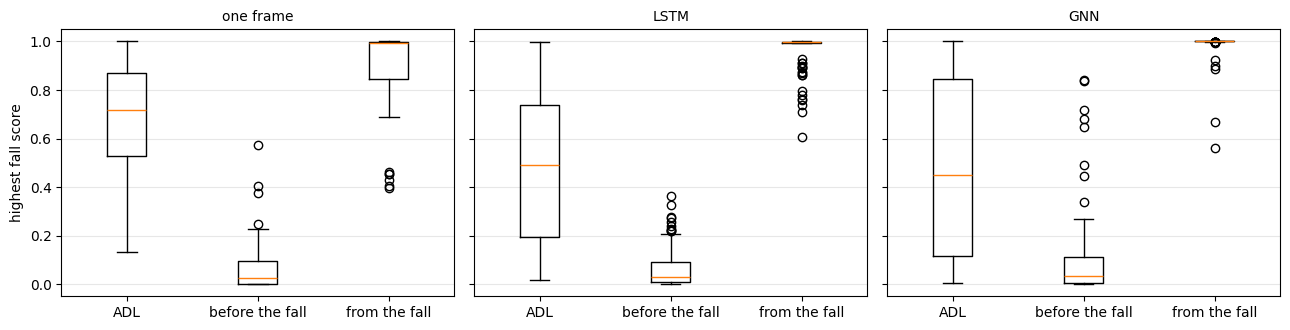

shortest beginnings (frames before the fall): [3, 10, 11, 12, 13]


In [11]:
start = skel[falling & fall_row].groupby("video").frame.min()
part = np.where(~fall_row, "ADL", np.where(skel.frame < skel.video.map(start).fillna(0), "before the fall", "from the fall"))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, n in zip(axes, MODELS):
    data = {"ADL": [], "before the fall": [], "from the fall": []}
    for s in range(3):
        top = smooth(results["fall", n, "strict", s][0].p1.to_numpy()).groupby([part, skel.video.to_numpy()]).max()
        for k in data: data[k].append(top[k])
    data = {k: pd.concat(v) for k, v in data.items()}
    ax.boxplot(list(data.values())); ax.set_xticklabels(list(data)); ax.set_title(n, fontsize=10); ax.grid(axis="y", alpha=0.3)
    print(f"{n}: median |", {k: round(float(v.median()), 2) for k, v in data.items()}, "| share above 0.5 |", {k: round(float((v > 0.5).mean()), 2) for k, v in data.items()})
axes[0].set_ylabel("highest fall score"); plt.tight_layout(); plt.show()
print("shortest beginnings (frames before the fall):", sorted((start - 1).tolist())[:5])

💡 **Interpretation:** before the fall the scores are low (median 0.02-0.04, above 0.5 in at most 6% of the videos) and from the fall they are high (median 0.99-1.0): the alarm does not come from the start of the video.
ADLs score higher than *before the fall*. But the fall videos' beginnings were training examples of *no fall*, so this check cannot exclude every effect of the office.

## Step 9 — Which videos are wrong, and how fast is the alarm?

We look at the LSTM and the GNN, and at the videos that were hard in part A.

In [12]:
print("network with the best validation average precision (Step 4):", best_val["fall"].idxmax())
hard, look, right = ["adl-31", "adl-34", "adl-35", "fall-01", "fall-03", "fall-07"], {}, {}
for n in ["LSTM", "GNN"]:
    wrong = pd.DataFrame({s: decided[n, s][0] != is_fall for s in range(3)}, index=videos).sum(axis=1)
    print(f"\n{n}: wrong in all 3 starts:", list(wrong.index[wrong == 3]), "\n     wrong in 1 or 2 starts:", list(wrong.index[(wrong > 0) & (wrong < 3)]))
    look[f"{n}: starts wrong (of 3)"] = wrong.loc[hard]
    right[n] = [[int((decided[n, s][0] == is_fall)[g == t].sum()) for t in range(1, 6)] for s in range(3)]
    delay = []
    for s in range(3):
        p, thr = smooth(results["fall", n, "strict", s][0].p1.to_numpy()).to_numpy(), decided[n, s][2]
        for v in videos[is_fall == 1]:
            idx = VIDEO_ROWS[v]; f, lab = skel.frame.to_numpy()[idx], skel.frame_label.to_numpy()[idx]
            hit = f[p[idx] > thr[strict_of[v]]]
            if len(hit): delay.append((hit.min() - f[lab == 1].min()) / 30)
    delay = np.array(delay)
    print(f"     alarm time compared with the first 'lying' frame: median {np.median(delay):.2f} s, middle half from {np.quantile(delay, .25):.2f} to {np.quantile(delay, .75):.2f} s ({len(delay)} alarms)",
          "| alarms before the fall starts:", int((delay < -1).sum()))
print("\nvideos right per test group, for the 3 starts | group sizes:", [int((g == t).sum()) for t in range(1, 6)])
for n in right: print(f"   {n}:", right[n])
pd.DataFrame(look).T

network with the best validation average precision (Step 4): GNN

LSTM: wrong in all 3 starts: ['adl-30', 'adl-38', 'adl-39'] 
     wrong in 1 or 2 starts: ['adl-01', 'adl-03', 'adl-05', 'adl-11', 'adl-13', 'adl-14', 'adl-16', 'adl-26', 'adl-40', 'fall-03']
     alarm time compared with the first 'lying' frame: median -0.40 s, middle half from -0.53 to -0.33 s (88 alarms) | alarms before the fall starts: 0

GNN: wrong in all 3 starts: ['adl-01', 'adl-03', 'adl-26', 'adl-33'] 
     wrong in 1 or 2 starts: ['adl-04', 'adl-05', 'adl-06', 'adl-07', 'adl-10', 'adl-11', 'adl-16', 'adl-22', 'adl-23', 'adl-30', 'adl-31', 'adl-32', 'adl-34', 'adl-35', 'adl-36', 'adl-37', 'adl-38', 'adl-39', 'adl-40', 'fall-03', 'fall-11', 'fall-25']
     alarm time compared with the first 'lying' frame: median -0.57 s, middle half from -0.70 to -0.40 s (87 alarms) | alarms before the fall starts: 1

videos right per test group, for the 3 starts | group sizes: [17, 18, 12, 12, 11]
   LSTM: [[16, 16, 11, 9, 11], 

,adl-31,adl-34,adl-35,fall-01,fall-03,fall-07
LSTM: starts wrong (of 3),0,0,0,0,2,0
GNN: starts wrong (of 3),1,1,1,0,1,0


💡 **Interpretation:** the LSTM is wrong in all 3 starts on only 3 ADLs (`adl-30`, `adl-38`, `adl-39`) and misses `fall-03` in 2 of 3 starts; the hard ADLs `adl-31/34/35` are now right. Its alarm comes **0.40 s before** the first *lying* frame (median), during the fall, and never before it starts.
The GNN gives about twice as many false alarms (12 against 6.3) and 1 alarm before the fall starts.

Let us look at the moment of the highest GNN score in the four ADLs that the GNN gets wrong in all 3 starts, and in `adl-30` (wrong in all 3 starts of the LSTM).

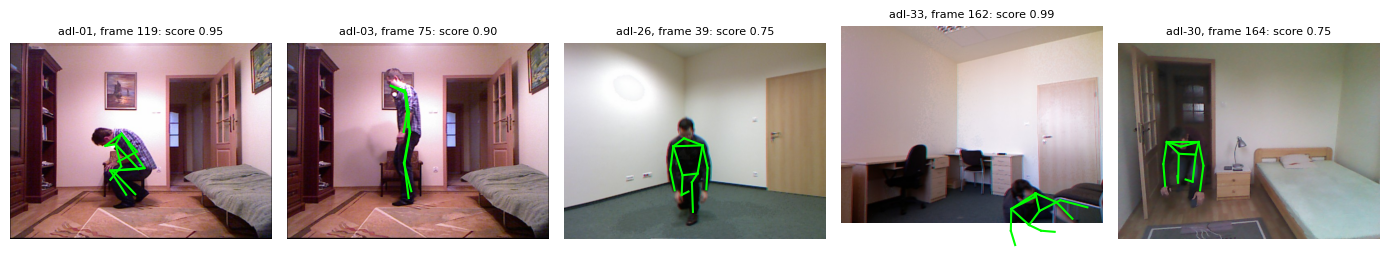

In [13]:
import cv2, re
def image_of(video, frame):
    f = {int(re.search(r"-(\d+)\.png$", q.name).group(1)): q for q in (ROOT / "rgb" / video).rglob("*.png")}
    return cv2.cvtColor(cv2.imread(str(f[frame])), cv2.COLOR_BGR2RGB)
score = smooth(np.mean([results["fall", "GNN", "strict", s][0].p1.to_numpy() for s in range(3)], axis=0)).to_numpy()
fig, axes = plt.subplots(1, 5, figsize=(14, 2.6))
for ax, v in zip(axes, ["adl-01", "adl-03", "adl-26", "adl-33", "adl-30"]):
    i = VIDEO_ROWS[v][np.argmax(score[VIDEO_ROWS[v]])]
    ax.imshow(image_of(v, skel.frame[i])); ax.axis("off"); ax.set_title(f"{v}, frame {skel.frame[i]}: score {score[i]:.2f}", fontsize=8)
    q = skel.loc[i, [f"{j}_{c}" for j in J for c in "xy"]].to_numpy(dtype=float).reshape(13, 2) * [640, 480]
    for a, b in BONES: ax.plot(q[[a, b], 0], q[[a, b], 1], color="lime", lw=1.5)
plt.tight_layout(); plt.show()

💡 **Interpretation:** in `adl-01`, `adl-26` and `adl-30` the person squats or bends down, as at the start of a fall, and in `adl-33` they are near the floor with a skeleton partly outside the image.
But in `adl-03` the person is **standing**: that false alarm is not explained. A window that ends here cannot use what comes after.

## Step 10 — Save for the final benchmark

In [14]:
name_of = lambda d: d[d.method.str.startswith("skeleton")].assign(network=lambda t: t.method.str.replace("skeleton: ", ""))
final = name_of(frame_scores).merge(sizes, on="network").merge(name_of(video_table).drop(columns="method"), on="network")
final.to_csv(PROC / "results_skeleton_nets.csv", index=False)
video_table.to_csv(PROC / "results_skeleton_videos.csv", index=False)
out = skel[["video", "frame", "frame_label"]].copy()
for (task, n, groups, s), (d, _) in results.items(): out[f"{task} {groups} {n} {s}"] = d[["p0", "p1", "p2"]].to_numpy().argmax(1) - 1 if task == "posture" else d.p1.to_numpy()
out.to_csv(PROC / "predictions_skeleton_nets.csv", index=False)
print(final.shape, out.shape)

(3, 16) (11936, 27)


💡 **Interpretation:** one line per network, and the predictions of every frame (2 tasks × 3 networks × 4 runs = 24 columns), ready for notebook 14 and the final benchmark.

## What we learned

1. **Skeletons over time are the best method so far for postures.** Strict macro F1 of the LSTM: **0.752** (0.723-0.787 over 3 starts) and accuracy 0.806, against 0.689 (MobileNetV2) and 0.784 (accuracy of colour + SVM). It is chosen on the validation groups too (0.800).
2. **Skeletons generalise better than images:** from random to strict groups the LSTM loses 0.06, the CNNs 0.16-0.19. A single skeleton frame (0.715) already beats the CNNs.
3. **Time matters for falls:** one frame gets 43/70 videos, the LSTM **63/70** (29.3 of 30 falls, 6.3 false alarms of 40). The CNNs with the weak decision of notebook 08 got 49/70.
4. **The LSTM is not clearly better than simple rules:** the state machine of notebook 10 gets 61/70 with a threshold chosen fairly, and its other thresholds were chosen by looking at all the videos. It is the fairest comparison we have, but it is not perfect.
5. **The GNN is unstable.** It ranks the videos best (AUC 0.966), but gets only 57/70 on average (53 to 60). A network first on validation (average precision 0.975) is not always first on the test.
6. **Some false alarms are real descents:** squatting or bending down (3 of the 5 examples), being near the floor (1). One (`adl-03`) is a standing person and is not explained. A window that ends in the middle of the movement cannot know if the person gets up again.
7. **The scores do not come from the *found* flag** (0.38 for postures), and the fall score is low before the fall starts.

**Limits:** all the falls are in one office, so the skeletons of the falls come from similar camera views. Only 70 videos (1 video = 1.4 points). The threshold is chosen on few validation videos. Every group is once the test and once the validation. When MediaPipe does not find the person, the LSTM is much weaker (0.59 against 0.77). Before the repeatable settings, the same start of the GNN gave 50, 60, 61 and 61 videos right in four trainings, so gaps of a few videos are not meaningful.

**Next notebook (13):** the new datasets: prepare them and make the train / test split.